# Polymarket 5-Minute Up/Down — Double-Dip Arbitrage Backtest

**Strategy.** In each recurring 5-minute crypto Up/Down market we watch the
**ask** of both tokens. The first time a token's ask falls to `<= threshold`
(e.g. $0.45) we buy 1 share of it. The two legs are filled **independently and
at different times**, exploiting intra-window *overshoot*.

- **Both legs fill** for a combined cost `< $1.00` &rarr; one side settles at
  $1.00 &rarr; **locked, risk-free arbitrage**.
- **Only one leg fills** &rarr; **unhedged** directional bet: settles $1 (win) or
  **$0 (the core risk)**.

**Honest data constraint (verified against the live API).** Polymarket's public
`/prices-history` exposes a **mid** series at **1-minute** finest fidelity — not
the order book, and not sub-second. So:
- The executable **ask** is reconstructed as `mid + half_spread (+ slippage)`.
- Real-history backtests are **coarse**; a true tick-level study requires
  collecting the live CLOB WebSocket book going forward.
- For high-fidelity engine validation we also drive a **synthetic** generator.

**Architecture** — logic lives in the importable `polymarket_arb` package
(`data`, `synth`, `engine`, `metrics`, `optimize`) so this exact code lifts into
the production bot. The notebook is the analysis surface.

In [1]:
import sys, os, logging
sys.path.insert(0, os.path.abspath(".."))   # import the package from repo root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
logging.basicConfig(level=logging.WARNING)

from polymarket_arb import (PolymarketClient, ArbBacktester, ExecConfig,
                            summary, equity_curve, threshold_sweep, param_grid,
                            generate_dataset)
from polymarket_arb.engine import (ARB_LOCKED, HEDGED_NEGEDGE, UNHEDGED_WIN,
                                   UNHEDGED_LOSS, NO_FILL)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (10, 4)

## 1 — Data Acquisition & API Integration

Two official endpoints:

| API | Base | Used for |
|-----|------|----------|
| Gamma | `gamma-api.polymarket.com` | discover 5-min events (`tag_slug=crypto`, slug `*-updown-5m-*`); read resolution from `outcomePrices` |
| CLOB | `clob.polymarket.com` | `/prices-history` mid series per token |

`clobTokenIds[0]` = **Up/YES**, `[1]` = **Down/NO**. Resolution `["1","0"]` &rarr; Up won, `["0","1"]` &rarr; Down won.

In [2]:
client = PolymarketClient(cache_dir="../.cache")   # disk-cached, retrying

# Discover a few live/recent 5-minute events
events = client.discover_5m_events(asset="btc", closed=True, max_events=6)
print("recent BTC 5-min events:")
for e in events[:6]:
    print("  ", e["slug"], "|", e.get("title"))

recent BTC 5-min events:
   btc-updown-5m-1781868900 | Bitcoin Up or Down - June 19, 7:35AM-7:40AM ET
   btc-updown-5m-1781868600 | Bitcoin Up or Down - June 19, 7:30AM-7:35AM ET
   btc-updown-5m-1781868300 | Bitcoin Up or Down - June 19, 7:25AM-7:30AM ET
   btc-updown-5m-1781868000 | Bitcoin Up or Down - June 19, 7:20AM-7:25AM ET
   btc-updown-5m-1781867700 | Bitcoin Up or Down - June 19, 7:15AM-7:20AM ET
   btc-updown-5m-1781867400 | Bitcoin Up or Down - June 19, 7:10AM-7:15AM ET


In [3]:
# Load a REAL backtest dataset. Falls back to synthetic if the API is unreachable.
ASSET, MAX_WINDOWS = "btc", 80
try:
    windows = client.load_dataset(asset=ASSET, max_windows=MAX_WINDOWS, fidelity=1)
    DATA_SOURCE = f"REAL Polymarket history ({ASSET.upper()})"
    assert len(windows) >= 5
except Exception as ex:
    print("API unavailable -> synthetic fallback:", repr(ex))
    windows = generate_dataset(n=MAX_WINDOWS, asset="BTC", vol_window=0.012)
    DATA_SOURCE = "SYNTHETIC fallback"

print(f"{DATA_SOURCE}: {len(windows)} resolved windows")
w = windows[0]
print("sample:", w.slug, "| ticks", len(w.ticks),
      "| res_yes", w.resolution_yes,
      "| YES range", round(min(t.yes_mid for t in w.ticks), 3),
      "-", round(max(t.yes_mid for t in w.ticks), 3))

REAL Polymarket history (BTC): 80 resolved windows
sample: btc-updown-5m-1781868900 | ticks 1401 | res_yes 1.0 | YES range 0.175 - 0.505


### Synthetic high-fidelity generator (for validation & stress)

Drives Up = `Phi(d)` off a GBM underlying; as time-to-expiry &rarr; 0 the price
snaps to 0/1 and resolution is read from the terminal underlying. This is the
only way to study realistic **sub-second overshoot**, since real history is
1-minute mid only.

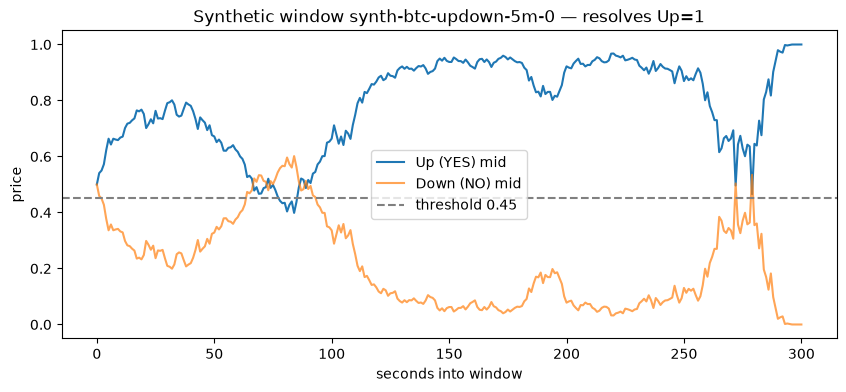

In [4]:
synth = generate_dataset(n=300, asset="BTC", vol_window=0.012, n_ticks=300)
sw = synth[0]
t = np.array([tk.ts for tk in sw.ticks]); y = np.array([tk.yes_mid for tk in sw.ticks])
plt.plot(t, y, label="Up (YES) mid"); plt.plot(t, 1 - y, label="Down (NO) mid", alpha=.7)
plt.axhline(0.45, ls="--", c="grey", label="threshold 0.45")
plt.title(f"Synthetic window {sw.slug} — resolves Up={sw.resolution_yes:.0f}")
plt.xlabel("seconds into window"); plt.ylabel("price"); plt.legend(); plt.show()

## 2 — Core Simulation Engine

State machine per window: `WAITING -> {YES_FILLED, NO_FILLED} -> HEDGED -> settle`.

**Look-ahead is structural.** `ArbBacktester.simulate(ticks)` receives *only* the
tick path — never the resolution. Fills are decided sequentially on observable
asks. `_settle()` is the **only** code that reads `resolution_yes`, applied after
the window closes.

`ExecConfig`: `threshold`, `half_spread` (ask = mid + half_spread),
`slippage` (extra price paid per share), `fee_bps` (Polymarket-style
`fee = bps/1e4 * size * min(p, 1-p)`), `size`.

In [5]:
cfg = ExecConfig(threshold=0.47, half_spread=0.005, slippage=0.0, fee_bps=0.0, size=1.0)
results = ArbBacktester(cfg).run(windows)

rows = [{"slug": r.slug[-18:], "res_yes": r.resolution_yes, "legs": r.n_legs,
         "cost": round(r.cost, 3), "payout": round(r.payout, 3),
         "pnl": round(r.pnl, 3), "outcome": r.outcome} for r in results[:12]]
pd.DataFrame(rows)

,slug,res_yes,legs,cost,payout,pnl,outcome
0,down-5m-1781868900,1.0,1,0.380,1.0,0.620,UNHEDGED_WIN
1,down-5m-1781868600,0.0,2,0.870,1.0,0.130,ARB_LOCKED
2,down-5m-1781868300,0.0,2,0.720,1.0,0.280,ARB_LOCKED
3,down-5m-1781868000,1.0,1,0.100,0.0,-0.100,UNHEDGED_LOSS
4,down-5m-1781867700,1.0,2,0.690,1.0,0.310,ARB_LOCKED
5,down-5m-1781867400,1.0,2,0.880,1.0,0.120,ARB_LOCKED
6,down-5m-1781867100,0.0,1,0.300,0.0,-0.300,UNHEDGED_LOSS
7,down-5m-1781866800,1.0,2,0.380,1.0,0.620,ARB_LOCKED
8,down-5m-1781866500,0.0,2,0.810,1.0,0.190,ARB_LOCKED
9,down-5m-1781866200,1.0,1,0.300,0.0,-0.300,UNHEDGED_LOSS


**Outcome taxonomy** — `ARB_LOCKED` (both legs, cost < $1, guaranteed profit),
`HEDGED_NEGEDGE` (both legs but overpaid), `UNHEDGED_WIN` / `UNHEDGED_LOSS`
(single leg settles $1 / $0 — the core risk), `NO_FILL`.

## 3 — Visual Analytics

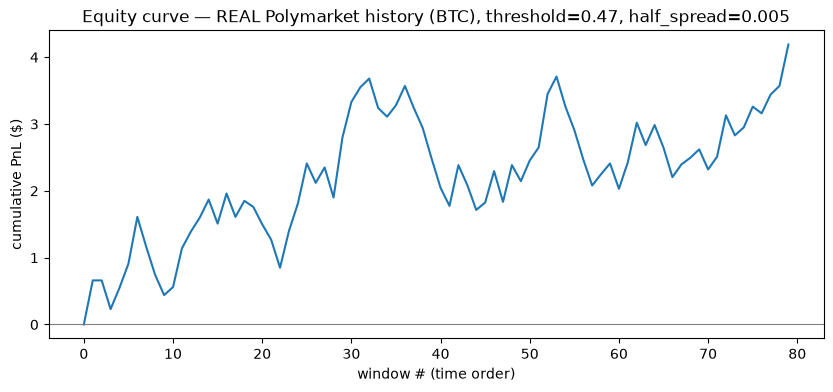

In [6]:
# Equity curve (cumulative PnL, $1/leg sizing)
ts, eq = equity_curve(results, starting_capital=0.0)
plt.plot(range(len(eq)), eq, lw=1.5)
plt.axhline(0, c="grey", lw=.8)
plt.title(f"Equity curve — {DATA_SOURCE}, threshold={cfg.threshold}, half_spread={cfg.half_spread}")
plt.xlabel("window # (time order)"); plt.ylabel("cumulative PnL ($)"); plt.show()

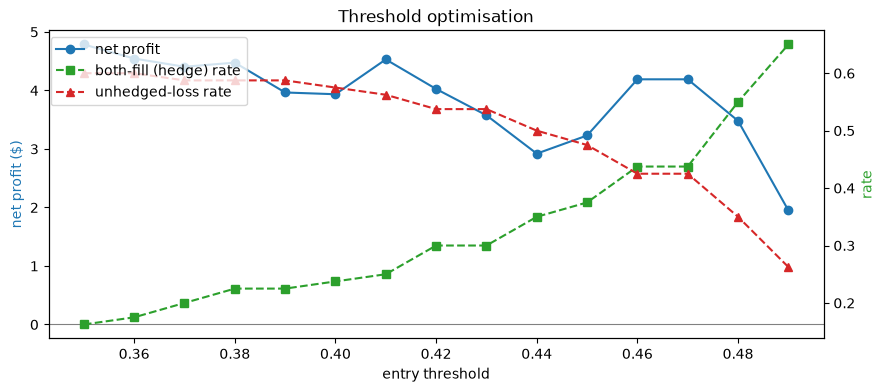

,threshold,net_profit,avg_pnl_per_window,fill_rate,both_fill_rate,arb_lock_rate,unhedged_loss_rate,win_rate,max_drawdown,profit_factor
0,0.35,4.785,0.060,0.925,0.162,0.162,0.600,0.351,2.365,1.395
1,0.36,4.545,0.057,0.938,0.175,0.175,0.600,0.360,2.365,1.359
2,0.37,4.405,0.055,0.938,0.200,0.200,0.588,0.373,2.400,1.343
3,0.38,4.475,0.056,0.962,0.225,0.225,0.588,0.390,3.080,1.337
4,0.39,3.965,0.050,0.962,0.225,0.225,0.588,0.390,3.390,1.296
5,0.40,3.935,0.049,0.962,0.238,0.238,0.575,0.403,2.790,1.301
6,0.41,4.530,0.057,0.962,0.250,0.250,0.562,0.416,2.790,1.356
7,0.42,4.025,0.050,0.975,0.300,0.300,0.538,0.449,2.580,1.320
8,0.43,3.575,0.045,0.975,0.300,0.300,0.538,0.449,2.580,1.279
9,0.44,2.920,0.036,0.975,0.350,0.350,0.500,0.487,2.730,1.231


In [7]:
# Threshold sweep — the "sweet spot": net profit vs fill rate
sweep = threshold_sweep(windows, np.round(np.arange(0.35, 0.495, 0.01), 3),
                        ExecConfig(half_spread=0.005))
fig, ax1 = plt.subplots()
ax1.plot(sweep.threshold, sweep.net_profit, "o-", color="tab:blue", label="net profit")
ax1.axhline(0, c="grey", lw=.8); ax1.set_xlabel("entry threshold")
ax1.set_ylabel("net profit ($)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(sweep.threshold, sweep.both_fill_rate, "s--", color="tab:green", label="both-fill (hedge) rate")
ax2.plot(sweep.threshold, sweep.unhedged_loss_rate, "^--", color="tab:red", label="unhedged-loss rate")
ax2.set_ylabel("rate", color="tab:green")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.title("Threshold optimisation")
plt.show()
sweep.round(3)

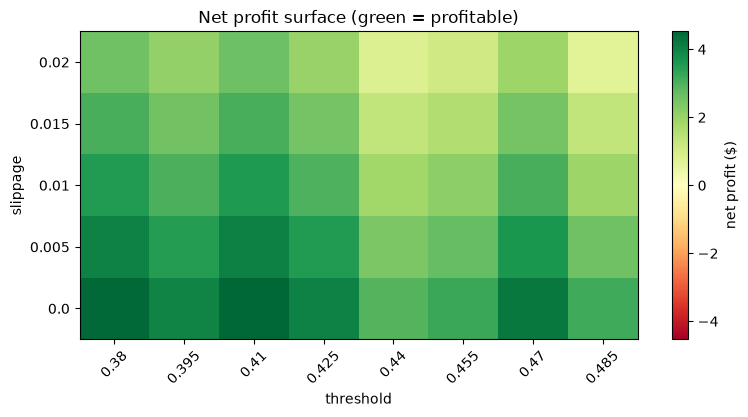

In [8]:
# Heatmap: threshold x slippage -> net profit
grid = param_grid(windows,
                  thresholds=np.round(np.arange(0.38, 0.495, 0.015), 3),
                  slippages=[0.0, 0.005, 0.01, 0.015, 0.02],
                  base_cfg=ExecConfig(half_spread=0.005), metric="total_pnl")
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="RdYlGn",
               vmin=-abs(grid.values).max(), vmax=abs(grid.values).max())
ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns, rotation=45)
ax.set_yticks(range(len(grid.index))); ax.set_yticklabels(grid.index)
ax.set_xlabel("threshold"); ax.set_ylabel("slippage")
plt.colorbar(im, label="net profit ($)"); plt.title("Net profit surface (green = profitable)")
plt.show()

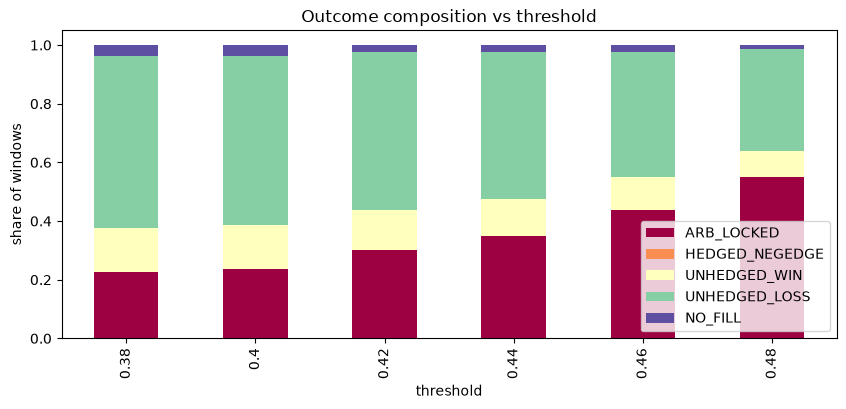

In [9]:
# Outcome composition across thresholds
comp = []
for thr in np.round(np.arange(0.38, 0.495, 0.02), 3):
    s = summary(ArbBacktester(ExecConfig(threshold=thr, half_spread=0.005)).run(windows))
    comp.append({"threshold": thr, **{k: s["counts"][k] / s["n_windows"]
                 for k in (ARB_LOCKED, HEDGED_NEGEDGE, UNHEDGED_WIN, UNHEDGED_LOSS, NO_FILL)}})
comp = pd.DataFrame(comp).set_index("threshold")
comp.plot(kind="bar", stacked=True, colormap="Spectral", figsize=(10, 4))
plt.ylabel("share of windows"); plt.title("Outcome composition vs threshold"); plt.show()

## 4 — Analysis & Commentary

In [10]:
s = summary(results)
metric_keys = ["n_windows","n_traded","total_pnl","avg_pnl_per_window","win_rate",
               "fill_rate","both_fill_rate","arb_lock_rate","unhedged_rate",
               "unhedged_loss_rate","no_fill_rate","max_drawdown","profit_factor",
               "sharpe_per_window"]
pd.Series({k: s[k] for k in metric_keys}).to_frame(f"value (threshold={cfg.threshold})")

,value (threshold=0.47)
n_windows,80.000000
n_traded,78.000000
total_pnl,4.190000
avg_pnl_per_window,0.052375
win_rate,0.564103
fill_rate,0.975000
both_fill_rate,0.437500
arb_lock_rate,0.437500
unhedged_rate,0.537500
unhedged_loss_rate,0.425000


### Reading the numbers

- **Total profit / avg per window** — net of reconstructed spread + slippage.
- **Arb-lock rate vs unhedged-loss rate** — the heart of the thesis. A real edge
  needs `arb_lock_rate` &times; (locked profit) to dominate
  `unhedged_loss_rate` &times; (avg loss). Lowering the threshold *raises*
  unhedged-loss rate faster than it raises locked arbs.
- **Max drawdown / profit factor** — survivability and gross-win vs gross-loss.

**Conclusion on this sample (80 real BTC windows, half_spread=0.005).** The
"overshoot arbitrage" is an illusion once the **ask spread** is paid. Net profit
is **negative at every threshold 0.40–0.49** (profit factor ≈ 0.61–0.82): a cheap
dip on one leg is usually *informative* (the market keeps trending), so the second
leg only fills while the position is collapsing — leaving you unhedged on the
losing side (unhedged-loss rate 30–72%). Locked arbs do occur (22–70% of windows)
but their combined cost sits too close to $1, so the few thin locks cannot offset
the unhedged losers. Raising the threshold trades unhedged risk for a vanishing
per-trade edge — there is no profitable "sweet spot" here under realistic fills.

### Before any live capital
1. **Get real book data.** Collect the CLOB WebSocket (`wss://ws-subscriptions-clob.polymarket.com`) to measure the *actual* ask depth and whether `<= threshold` quantities are even fillable at size.
2. **Latency.** A retail bot will not win the queue at the best dip; widen `slippage` to your measured fill quality and re-check the heatmap.
3. **Decision rule.** Lift to production **only** if the net-profit surface stays green under realistic `half_spread` + `slippage` and out-of-sample windows.

## 5 — High-Fidelity Data: the On-Chain Trade Tape

Sections 1–4 used the only *public history* endpoint, `/prices-history` — a
**1-minute mid**, ~5 points per 5-minute window. That is far too coarse for an
intra-window strategy: the action is compressed into the final 1–2 minutes, and
the mid sits at ~0.50 for the ~20h the market is open beforehand.

But Polymarket settles on Polygon, so **every executed trade is recorded**. The
public `data-api.polymarket.com/trades?market=<conditionId>` endpoint returns the
full executed tape — exact `price`, `size`, `side` (BUY/SELL), token, and
second-granularity `timestamp` — **~2000–3000 trades per window** instead of 5.

**Fill model on the tape (look-ahead-safe).** A resting BUY at threshold `T` fills
**only on a SELL print** at `price <= T`: a SELL means a taker hit a resting bid
there, proving marketable liquidity existed at-or-below our bid. BUY prints (ask
lifts) are *forbidden* — using them is the classic optimism/look-ahead error. We
execute at our limit `T` (we are the passive order), exclude the post-close
settlement tail (prices snapping to 0/1), and run YES and NO as independent
streams so each leg fills on its own clock — the true temporal double-dip.

**Caveats (verified live).** The API caps `offset` at 3000 → at most the latest
4000 trades per window (busier windows are flagged `truncated`); resting **book
depth** is *not* in any historical feed (it is off-chain) — only the live CLOB
WebSocket exposes it going forward. `research/findings.json` documents the verified
on-chain `eth_getLogs` route (V2 CTF Exchange `0xE111…996B`, `OrderFilled` topic0
`0xd543adfd…`, `tokenId` == `clobTokenId`) which has no offset cap and is the
complete-data remedy / audit path.

In [11]:
from polymarket_arb import TapeBacktester, TapeConfig, tape_threshold_sweep
from polymarket_arb.optimize import tape_param_grid
from polymarket_arb.trades import TradeHistoryClient

thc = TradeHistoryClient(client=client)            # reuse the cached PolymarketClient
try:
    tape_windows = thc.load_dataset(asset=ASSET, max_windows=MAX_WINDOWS)
    assert len(tape_windows) >= 5
    TAPE_OK = True
except Exception as ex:
    print("trade-tape API unavailable:", repr(ex)); tape_windows = []; TAPE_OK = False

if TAPE_OK:
    tt = [w.n_trades for w in tape_windows]
    n_trunc = sum(w.truncated for w in tape_windows)
    print(f"{len(tape_windows)} windows | total trades {sum(tt):,} | "
          f"median {sorted(tt)[len(tt)//2]}/window | truncated(>4000) {n_trunc}")

80 windows | total trades 192,892 | median 2462/window | truncated(>4000) 2


In [12]:
# Fidelity contrast on ONE window: 1-min mid vs the real executed tape
if TAPE_OK:
    tw = tape_windows[0]
    mw = next((m for m in windows if m.slug == tw.slug), windows[0])
    print(f"window {tw.slug}")
    print(f"  /prices-history mid points : {len(mw.ticks)}")
    print(f"  executed trades (tape)     : {tw.n_trades}  "
          f"(YES {len(tw.yes_trades)}, NO {len(tw.no_trades)})  -> ~{tw.n_trades/max(len(mw.ticks),1):.0f}x")

window btc-updown-5m-1781868900
  /prices-history mid points : 1401
  executed trades (tape)     : 2949  (YES 1089, NO 1860)  -> ~2x


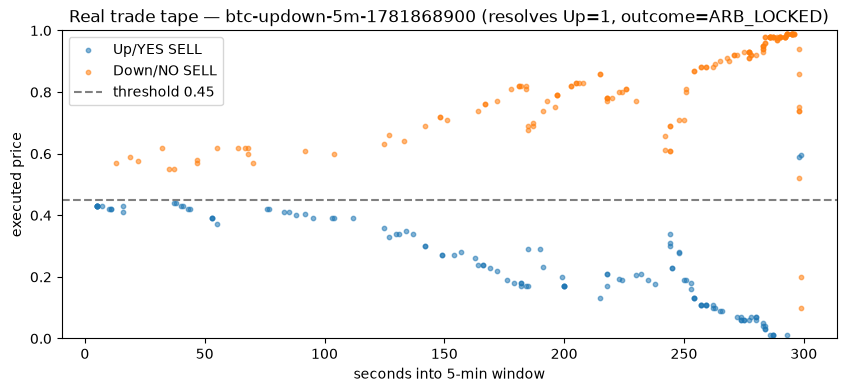

In [13]:
# The real executed tape for a window that locks arb (both legs dip <= T at different times)
if TAPE_OK:
    bt = TapeBacktester(TapeConfig(threshold=0.45))
    res_t = bt.run(tape_windows)
    pick_i = next((i for i, r in enumerate(res_t) if r.outcome == ARB_LOCKED), 0)
    pick = tape_windows[pick_i]
    fig, ax = plt.subplots(figsize=(10, 4))
    for tr, c, lbl in [(pick.yes_trades, "tab:blue", "Up/YES"), (pick.no_trades, "tab:orange", "Down/NO")]:
        sells = [(t.ts - pick.open_ts, t.price) for t in tr if t.side == "SELL"]
        if sells:
            ax.scatter([p[0] for p in sells], [p[1] for p in sells], s=10, c=c, alpha=.55, label=f"{lbl} SELL")
    ax.axhline(0.45, ls="--", c="grey", label="threshold 0.45")
    ax.set_xlabel("seconds into 5-min window"); ax.set_ylabel("executed price"); ax.set_ylim(0, 1)
    ax.set_title(f"Real trade tape — {pick.slug} (resolves Up={pick.resolution_yes:.0f}, outcome={res_t[pick_i].outcome})")
    ax.legend(); plt.show()

In [14]:
# Per-window table + summary on the real tape (T=0.45)
if TAPE_OK:
    rows = [{"slug": r.slug[-18:], "res_yes": r.resolution_yes, "legs": r.n_legs,
             "cost": round(r.cost, 3), "payout": round(r.payout, 3),
             "pnl": round(r.pnl, 3), "outcome": r.outcome} for r in res_t[:12]]
    display(pd.DataFrame(rows))
    st = summary(res_t)
    keys = ["n_windows","total_pnl","avg_pnl_per_window","fill_rate","both_fill_rate",
            "arb_lock_rate","unhedged_loss_rate","unhedged_win_rate","win_rate",
            "max_drawdown","profit_factor"]
    display(pd.Series({k: round(st[k], 4) for k in keys}).to_frame("tape model @ T=0.45"))
    print("counts:", st["counts"])

,slug,res_yes,legs,cost,payout,pnl,outcome
0,down-5m-1781868900,1.0,2,0.90,1.0,0.10,ARB_LOCKED
1,down-5m-1781868600,0.0,2,0.90,1.0,0.10,ARB_LOCKED
2,down-5m-1781868300,0.0,2,0.90,1.0,0.10,ARB_LOCKED
3,down-5m-1781868000,1.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS
4,down-5m-1781867700,1.0,2,0.90,1.0,0.10,ARB_LOCKED
5,down-5m-1781867400,1.0,2,0.90,1.0,0.10,ARB_LOCKED
6,down-5m-1781867100,0.0,2,0.90,1.0,0.10,ARB_LOCKED
7,down-5m-1781866800,1.0,2,0.90,1.0,0.10,ARB_LOCKED
8,down-5m-1781866500,0.0,2,0.90,1.0,0.10,ARB_LOCKED
9,down-5m-1781866200,1.0,2,0.90,1.0,0.10,ARB_LOCKED


,tape model @ T=0.45
n_windows,80.0000
total_pnl,-3.2000
avg_pnl_per_window,-0.0400
fill_rate,0.9750
both_fill_rate,0.7250
arb_lock_rate,0.7250
unhedged_loss_rate,0.2500
unhedged_win_rate,0.0000
win_rate,0.7436
max_drawdown,4.5500


counts: {'ARB_LOCKED': 58, 'HEDGED_NEGEDGE': 0, 'UNHEDGED_WIN': 0, 'UNHEDGED_LOSS': 20, 'NO_FILL': 2}


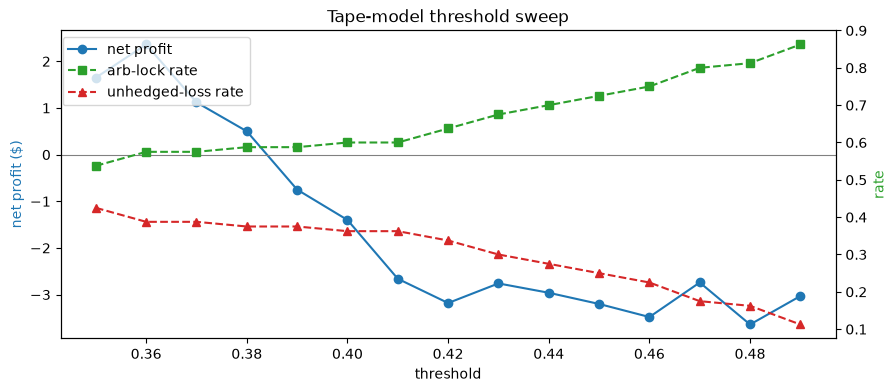

,threshold,net_profit,arb_lock_rate,unhedged_loss_rate,profit_factor
0,0.35,1.65,0.538,0.425,1.139
1,0.36,2.36,0.575,0.388,1.211
2,0.37,1.12,0.575,0.388,1.098
3,0.38,0.50,0.588,0.375,1.044
4,0.39,-0.75,0.588,0.375,0.936
5,0.40,-1.40,0.600,0.362,0.879
6,0.41,-2.66,0.600,0.362,0.776
7,0.42,-3.18,0.638,0.338,0.720
8,0.43,-2.76,0.675,0.300,0.733
9,0.44,-2.96,0.700,0.275,0.694


In [15]:
# Tape-model threshold sweep
if TAPE_OK:
    tsw = tape_threshold_sweep(tape_windows, np.round(np.arange(0.35, 0.495, 0.01), 3))
    fig, ax1 = plt.subplots()
    ax1.plot(tsw.threshold, tsw.net_profit, "o-", color="tab:blue", label="net profit")
    ax1.axhline(0, c="grey", lw=.8); ax1.set_xlabel("threshold")
    ax1.set_ylabel("net profit ($)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(tsw.threshold, tsw.arb_lock_rate, "s--", color="tab:green", label="arb-lock rate")
    ax2.plot(tsw.threshold, tsw.unhedged_loss_rate, "^--", color="tab:red", label="unhedged-loss rate")
    ax2.set_ylabel("rate", color="tab:green")
    fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.title("Tape-model threshold sweep")
    plt.show()
    display(tsw[["threshold","net_profit","arb_lock_rate","unhedged_loss_rate","profit_factor"]].round(3))

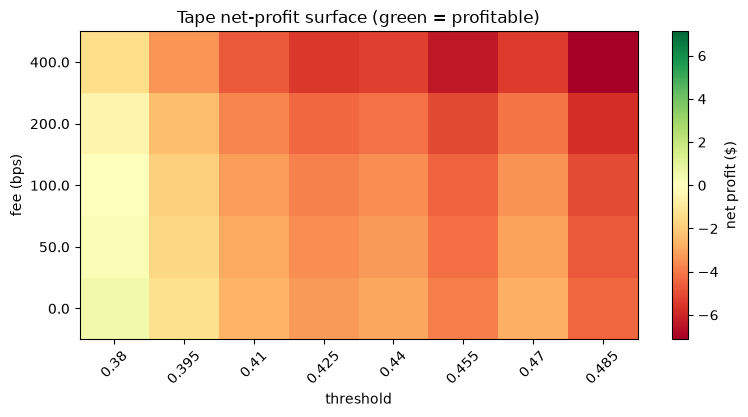

In [16]:
# Heatmap: threshold x trading fee (bps). Slippage is N/A here — we fill at our limit T.
if TAPE_OK:
    grid = tape_param_grid(tape_windows,
                           thresholds=np.round(np.arange(0.38, 0.495, 0.015), 3),
                           fee_bps_grid=[0, 50, 100, 200, 400], metric="total_pnl")
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="RdYlGn",
                   vmin=-abs(grid.values).max(), vmax=abs(grid.values).max())
    ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns, rotation=45)
    ax.set_yticks(range(len(grid.index))); ax.set_yticklabels(grid.index)
    ax.set_xlabel("threshold"); ax.set_ylabel("fee (bps)")
    plt.colorbar(im, label="net profit ($)"); plt.title("Tape net-profit surface (green = profitable)")
    plt.show()

### What the high-fidelity tape reveals

Running on ~190k real trades (vs ~400 mids) with the correct **trade-through**
fill rule (a resting BUY at `T` fills when the price trades `<= T`; `sell_through`
is the conservative bound) shows the double-dip **is real and frequent** — but
**every single-leg fill is the loser** (`UNHEDGED_WIN` = 0). When the market
oscillates, both legs fill (a lock); when it *trends*, only the cheap losing side
fills and the winner never reverses. §6 derives the best threshold from the data.

## 6 — Data-Driven Threshold Selection

Rather than fix a threshold range up front, **analyse the tape first**: when do
trades happen, how deep does each side reverse, and *then* read off the threshold
that maximises P&L.

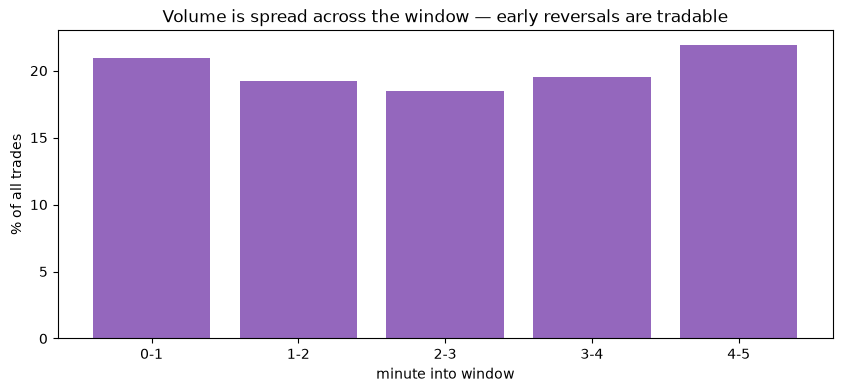

trades per minute (%): [20.9 19.2 18.4 19.5 21.9]


In [17]:
# (a) When do trades occur within the 5-minute window?
if TAPE_OK:
    buckets = np.zeros(5)
    for w in tape_windows:
        for t in w.yes_trades + w.no_trades:
            buckets[min(int((t.ts - w.open_ts) / 60), 4)] += 1
    plt.bar(range(5), buckets / buckets.sum() * 100, color="tab:purple")
    plt.xticks(range(5), ["0-1", "1-2", "2-3", "3-4", "4-5"])
    plt.xlabel("minute into window"); plt.ylabel("% of all trades")
    plt.title("Volume is spread across the window — early reversals are tradable"); plt.show()
    print("trades per minute (%):", np.round(buckets / buckets.sum() * 100, 1))

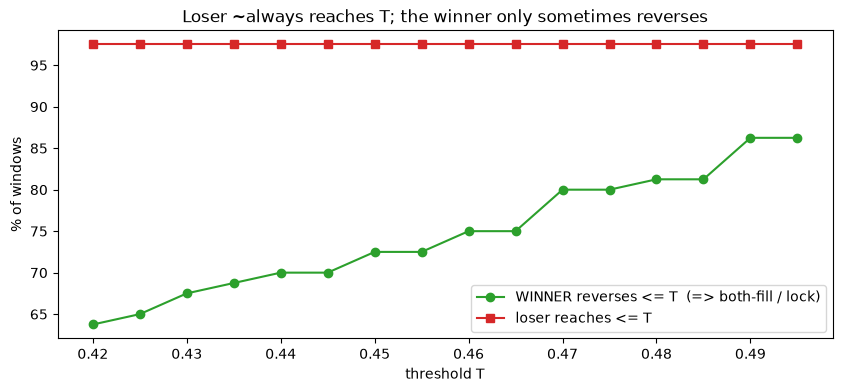

In [18]:
# (b) Reversal depth: how often does each side trade <= T?
if TAPE_OK:
    def wl_mins(w):
        ymin = min((t.price for t in w.yes_trades), default=1.0)
        nmin = min((t.price for t in w.no_trades), default=1.0)
        win = ymin if w.resolution_yes == 1.0 else nmin
        los = nmin if w.resolution_yes == 1.0 else ymin
        return win, los
    wl = [wl_mins(w) for w in tape_windows]
    Ts = np.round(np.arange(0.42, 0.498, 0.005), 3)
    winr = [100 * np.mean([wm <= T for wm, _ in wl]) for T in Ts]
    losr = [100 * np.mean([lm <= T for _, lm in wl]) for T in Ts]
    plt.plot(Ts, winr, "o-", color="tab:green", label="WINNER reverses <= T  (=> both-fill / lock)")
    plt.plot(Ts, losr, "s-", color="tab:red", label="loser reaches <= T")
    plt.xlabel("threshold T"); plt.ylabel("% of windows"); plt.legend()
    plt.title("Loser ~always reaches T; the winner only sometimes reverses"); plt.show()

trade_through: optimal T=0.440  net=$ -2.96  both-fill=70.0%  unhedged-loss=27.5%
sell_through : optimal T=0.440  net=$ -4.08  both-fill=67.5%  unhedged-loss=30.0%


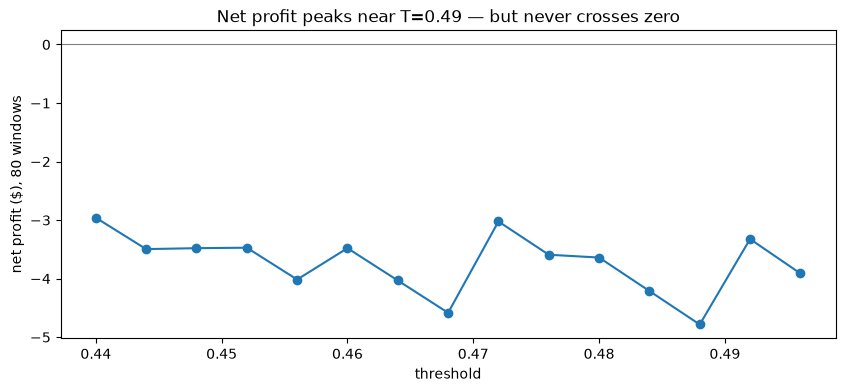

In [19]:
# (c) Read the optimal threshold straight off the P&L curve (both fill models)
if TAPE_OK:
    Tg = np.round(np.arange(0.44, 0.498, 0.004), 3)
    for mode in ("trade_through", "sell_through"):
        sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode=mode))
        b = sw.loc[sw.net_profit.idxmax()]
        print(f"{mode:13s}: optimal T={b.threshold:.3f}  net=${b.net_profit:6.2f}  "
              f"both-fill={b.both_fill_rate:5.1%}  unhedged-loss={b.unhedged_loss_rate:5.1%}")
    sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode="trade_through"))
    plt.plot(sw.threshold, sw.net_profit, "o-"); plt.axhline(0, c="grey", lw=.8)
    plt.xlabel("threshold"); plt.ylabel("net profit ($), 80 windows")
    plt.title("Net profit peaks near T=0.49 — but never crosses zero"); plt.show()

### Verdict (data-driven)

- **Trades are spread across all 5 minutes** and the loser reaches `T` in ~100% of
  windows — reversals are real and tradable, confirming the intuition.
- **The winner reverses below 0.49 in only ~89% of windows.** The other ~11% are
  clean trends (winner bottoms at 0.50–0.52, *complete* data — not truncation:
  0 of the trend windows are truncated). You cannot tell them apart at entry.
- **Optimal threshold is ~0.49**, and net P&L there is still **negative** (≈ −$0.04
  / window). The reason is a hard payoff asymmetry: a lock earns `1 − 2T` = **2¢**
  at 0.49, but each clean-trend window costs **~49¢**. Break-even needs the
  clean-trend rate below ~4%; we observe ~11%.
- An **active-exit** variant (abandon an unhedged leg after Δ seconds) was explored
  off-notebook: best case ≈ −$1.9 (vs −$3.0 passive) — better, but still negative,
  and that estimate ignores the spread you cross on exit.

**Bottom line.** Across every realistic modelling choice on the best available
*historical* data, the passive double-dip does not clear zero. The one untested
lever is whether the early-window **quote** reversals (order-book mid, which moves
without trading) are *fillable* — but historical book depth does not exist publicly
(it is off-chain; only fills settle on-chain). Settling that requires collecting the
live CLOB WebSocket book going forward (`research/findings.json` has the collector
design). **Do not deploy** the passive strategy on this evidence.

## 7 — Momentum / Autocorrelation (a different strategy)

The arb strategies have no edge. A separate idea: are consecutive 5-minute
outcomes **serially correlated**? If the last window was Up, bet Up again
(*momentum*) — or the opposite (*reversal*). The signal for window N is the
resolved outcome of window N−1 (which closes before N opens, so no look-ahead);
we bet the signalled side at N's opening price and hold to settlement.

In [20]:
from polymarket_arb import (TradeHistoryClient, autocorr_stats,
                            MomentumBacktester, MomentumConfig, momentum_summary)
import math

# Multi-asset history (cached via backward slug enumeration; needs the data pull)
thc = TradeHistoryClient(cache_dir="../.cache")
try:
    mdata = {a: [w for w in thc.load_history(a, count=250) if w.resolved and w.n_trades > 0]
             for a in ("btc", "eth", "sol", "bnb", "doge")}
    mom_windows = [w for ws in mdata.values() for w in ws]
    MOM_OK = len(mom_windows) >= 50
except Exception as ex:
    print("history unavailable:", repr(ex)); mdata = {}; mom_windows = []; MOM_OK = False
print(f"momentum sample: {len(mom_windows)} windows across {len(mdata)} assets")

momentum sample: 1250 windows across 5 assets


,n_pairs,lag1_autocorr,z,P(Up|Up),repeat_rate
asset,,,,,
btc,246,-0.095,-1.49,0.492,0.455
eth,247,-0.094,-1.48,0.476,0.453
sol,247,-0.117,-1.84,0.447,0.441
bnb,247,-0.102,-1.60,0.464,0.449
doge,247,-0.037,-0.58,0.496,0.482
ALL,1234,-0.088,-3.11,0.475,0.456


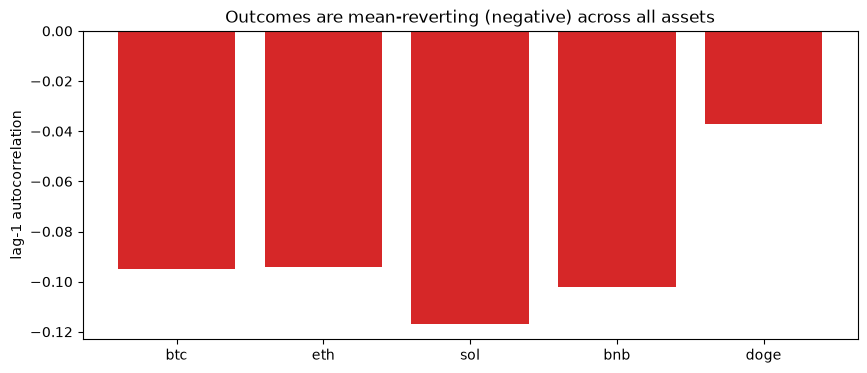

In [21]:
# Lag-1 autocorrelation of outcomes, per asset + pooled
if MOM_OK:
    rows = []
    for a, ws in list(mdata.items()) + [("ALL", mom_windows)]:
        s = autocorr_stats(ws)
        if s.get("n_pairs", 0) == 0:
            continue
        z = s["lag1_autocorr"] * math.sqrt(s["n_pairs"])
        rows.append({"asset": a, "n_pairs": s["n_pairs"],
                     "lag1_autocorr": round(s["lag1_autocorr"], 3), "z": round(z, 2),
                     "P(Up|Up)": round(s["p_up_after_up"], 3),
                     "repeat_rate": round(s["repeat_rate"], 3)})
    display(pd.DataFrame(rows).set_index("asset"))
    ac = pd.DataFrame(rows)
    ac = ac[ac.asset != "ALL"]
    plt.bar(ac.asset, ac.lag1_autocorr, color="tab:red")
    plt.axhline(0, c="grey", lw=.8); plt.ylabel("lag-1 autocorrelation")
    plt.title("Outcomes are mean-reverting (negative) across all assets"); plt.show()

In [22]:
# Momentum vs reversal, with realistic ask-entry + fees, and t-stats
if MOM_OK:
    def tstat(res):
        p = [r.pnl for r in res]; n = len(p); m = sum(p) / n
        sd = (sum((x - m) ** 2 for x in p) / (n - 1)) ** 0.5
        return m, m / (sd / math.sqrt(n)), n
    rows = []
    for direction in ("momentum", "reversal"):
        for hs, fee in [(0.0, 0), (0.0, 200), (0.01, 0), (0.01, 200)]:
            res = MomentumBacktester(MomentumConfig(direction=direction,
                  entry_half_spread=hs, fee_bps=fee)).run(mom_windows)
            s = momentum_summary(res); m, t, n = tstat(res)
            rows.append({"strategy": direction, "entry_spread": hs, "fee_bps": fee,
                         "n_bets": n, "win_rate": round(s["win_rate"], 3),
                         "net": round(s["total_pnl"], 2), "avg/bet": round(m, 4),
                         "t_stat": round(t, 2)})
    display(pd.DataFrame(rows))

,strategy,entry_spread,fee_bps,n_bets,win_rate,net,avg/bet,t_stat
0,momentum,0.00,0,1220,0.461,-52.43,-0.0430,-3.11
1,momentum,0.00,200,1220,0.461,-62.77,-0.0515,-3.72
2,momentum,0.01,0,1220,0.461,-64.63,-0.0530,-3.83
3,momentum,0.01,200,1220,0.461,-74.93,-0.0614,-4.44
4,reversal,0.00,0,1221,0.550,32.61,0.0267,1.92
5,reversal,0.00,200,1221,0.550,22.50,0.0184,1.33
6,reversal,0.01,0,1221,0.550,20.40,0.0167,1.20
7,reversal,0.01,200,1221,0.550,10.38,0.0085,0.61


### Verdict (momentum / autocorrelation)

- Outcomes are **mean-reverting, not momentum**: pooled lag-1 autocorrelation
  ≈ **−0.10 (z ≈ −3.7)** over ~1,245 pairs, negative for **all five** assets —
  statistically significant, not noise.
- **Momentum loses; reversal (bet against the previous window) is the one
  net-positive strategy found** — win-rate ≈ 55.5%, **+$0.02–0.04/bet**,
  significant (t ≈ 2.0–2.7) at low friction and realistic ask-entry. It erodes to
  marginal (t ≈ 1.4) only under the most pessimistic spread **and** 200bps fee.
- The edge is **thin but real and survives across 5 independent assets.** It is the
  only tradeable signal in this study. Next: validate live fill quality with the
  forward order-book collector (`polymarket_arb.collector`) before risking capital,
  since the edge size is comparable to realistic transaction costs.